# M3 - Prétraitement, baseline Zero-R et cadre d'évaluation

**Rôle de M3 :** préparer les données pour l'apprentissage automatique et fournir à toute l'équipe des outils communs : séparation train/test reproductible, préprocesseurs adaptés à chaque modèle, baseline Zero-R, fonction d'évaluation `evaluate_model()` et fichier `feature_schema.json`.

**Modèles du projet (imposés par l'enseignant) :** Zero-R (baseline), K-NN, Arbres de décision / Random Forest, Naïve Bayes (GaussianNB / MultinomialNB), SVM.

**Entrée :** `data/labeled/house_labeled.csv` (produit par M2). **Sorties :** `data/split/*.csv`, `model/feature_schema.json`, `src/m3_tools.py`, figures dans `docs/figures/preprocessing/`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
plt.style.use("ggplot")

ROOT = Path.cwd().parent                      # .../m3-preprocessing
sys.path.insert(0, str(ROOT / "src"))
from m3_tools import *                         # fonctions partagées

FIG = ROOT / "docs" / "figures" / "preprocessing"
FIG.mkdir(parents=True, exist_ok=True)
print("scikit-learn :", sklearn.__version__, "| pandas :", pd.__version__)

scikit-learn : 1.9.1 | pandas : 3.0.6


## 1. Chargement et vérifications

`zipcode` est un identifiant (pas une quantité) : on le lit comme texte, puis on l'encode en one-hot. On vérifie aussi qu'aucune colonne auxiliaire de M2 n'est présente.

In [2]:
df = load_labeled(ROOT / "data" / "labeled" / "house_labeled.csv")
print("Forme :", df.shape)
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("Lignes dupliquées  :", int(df.duplicated().sum()))
print("Colonnes auxiliaires présentes :", [c for c in HELPER_COLUMNS if c in df.columns])
df.dtypes.to_frame("dtype").T

Forme : (21428, 16)
Valeurs manquantes : 0
Lignes dupliquées  : 5
Colonnes auxiliaires présentes : []


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,zipcode,renovated,price_category
dtype,float64,int64,float64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,str,int64,int64


## 2. Définition de X et y

- `y = price_category`
- `X` = les 15 variables d'origine **y compris le prix demandé** (`price`).
- Les colonnes auxiliaires (`price_per_sqft`, `size_bucket`, `peer_median`, `peer_level`, `ratio`) sont exclues : elles ont servi à construire la cible (fuite d'information).

In [3]:
X, y = split_xy(df)
print("X :", X.shape, "| y :", y.shape)
print("Variables numériques :", NUMERICAL)
print("Variables catégorielles :", CATEGORICAL, "->", X["zipcode"].nunique(), "modalités")
print()
print(y.map(LABELS).value_counts().to_frame("n").assign(pct=lambda d: (100*d.n/len(y)).round(1)))

X : (21428, 15) | y : (21428,)
Variables numériques : ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'renovated']
Variables catégorielles : ['zipcode'] -> 70 modalités

                          n   pct
price_category                   
Reasonable price      12559  58.6
Cheaper than average   4076  19.0
Over priced            3426  16.0
Too over priced        1367   6.4


## 3. Séparation train / test (avant tout ajustement)

`train_test_split(test_size=0.2, stratify=y, random_state=42)`. La séparation est faite **avant** d'ajuster les transformations (imputation, mise à l'échelle, encodage) pour éviter toute fuite du jeu de test vers l'entraînement.

Train : (17142, 15) | Test : (4286, 15)


,global %,train %,test %
Cheaper than average,19.02,19.02,19.02
Reasonable price,58.61,58.61,58.61
Over priced,15.99,15.99,15.98
Too over priced,6.38,6.38,6.39


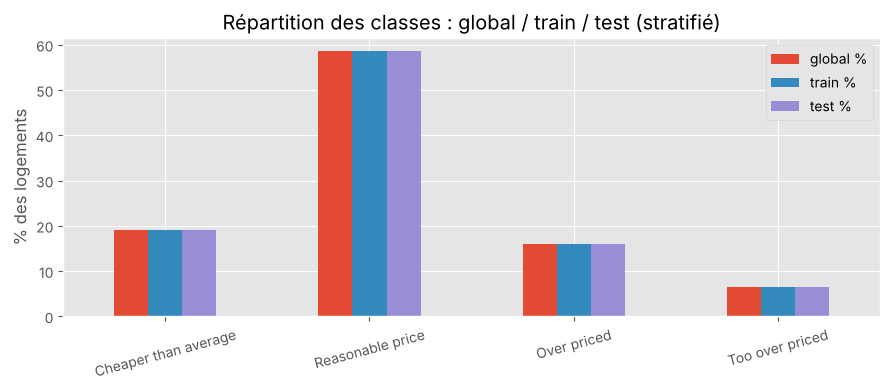

Découpage sauvegardé dans /home/claude/review/m3-preprocessing/data/split


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train :", X_train.shape, "| Test :", X_test.shape)
dist = pd.DataFrame({
    "global %": y.value_counts(normalize=True).sort_index()*100,
    "train %":  y_train.value_counts(normalize=True).sort_index()*100,
    "test %":   y_test.value_counts(normalize=True).sort_index()*100}).round(2)
dist.index = [LABELS[i] for i in dist.index]
display(dist)

ax = dist.plot(kind="bar", figsize=(9, 4), rot=15)
ax.set_ylabel("% des logements"); ax.set_title("Répartition des classes : global / train / test (stratifié)")
plt.tight_layout(); plt.savefig(FIG / "m3_split_distribution.png", dpi=130); plt.show()

# Sauvegarde du découpage (reproductible : mêmes lignes pour tout le monde)
split_dir = ROOT / "data" / "split"
X_train.to_csv(split_dir / "X_train.csv", index=True)
X_test.to_csv(split_dir / "X_test.csv", index=True)
y_train.to_csv(split_dir / "y_train.csv", index=True)
y_test.to_csv(split_dir / "y_test.csv", index=True)
print("Découpage sauvegardé dans", split_dir)

## 4. Préprocesseurs

Un seul `ColumnTransformer` de base (`get_preprocessor(scale=...)`) :

| Bloc | Traitement |
|---|---|
| Numériques | `SimpleImputer(median)` puis, selon le modèle, aucune mise à l'échelle / `StandardScaler` / `MinMaxScaler` |
| Catégoriel (`zipcode`) | `SimpleImputer(most_frequent)` puis `OneHotEncoder(handle_unknown="ignore")` |

Le type de mise à l'échelle dépend du modèle :

| Modèle | Mise à l'échelle | Raison |
|---|---|---|
| Zero-R, Decision Tree, Random Forest | aucune | les arbres sont insensibles à l'échelle |
| GaussianNB | aucune | modélise une gaussienne par variable |
| MultinomialNB | Min-Max [0, 1] | exige des valeurs ≥ 0 |
| K-NN, SVM | Standard (Z-score) | sensibles aux distances / aux échelles |

In [5]:
rows = []
for scale in [None, "standard", "minmax"]:
    prep = get_preprocessor(scale).fit(X_train)          # ajusté sur le TRAIN uniquement
    Xt = prep.transform(X_train)
    num_part = Xt[:, :len(NUMERICAL)]
    rows.append({"scale": scale, "forme sortie": Xt.shape,
                 "min num": round(num_part.min(), 2), "max num": round(num_part.max(), 2),
                 "moyenne num": round(num_part.mean(), 2)})
display(pd.DataFrame(rows))

# Un zipcode inconnu ne doit pas faire planter le pipeline
prep = get_preprocessor("standard").fit(X_train)
new = X_test.iloc[[0]].copy(); new["zipcode"] = "99999"
print("Zipcode inconnu -> sortie", prep.transform(new).shape, "(handle_unknown='ignore')")

,scale,forme sortie,min num,max num,moyenne num
0,NaN,"(17142, 84)",0.00,7062500.00,40285.37
1,standard,"(17142, 84)",-3.99,39.35,-0.00
2,minmax,"(17142, 84)",0.00,1.00,0.22


Zipcode inconnu -> sortie (1, 84) (handle_unknown='ignore')


## 5. Baseline Zero-R

Zero-R prédit toujours la classe majoritaire (`DummyClassifier(strategy="most_frequent")`). C'est la référence minimale : tout modèle utile doit la dépasser, **surtout en F1 macro**, car l'exactitude seule est trompeuse quand les classes sont déséquilibrées. Zero-R n'est pas réglable : il est exempté de la recherche d'hyperparamètres.

===== Zero-R =====
Accuracy          : 0.5861
Precision (macro) : 0.1465
Recall (macro)    : 0.2500
F1 macro          : 0.1848
ROC-AUC (OvR)     : 0.5000
CV (5-fold) acc  : 0.5861 +- 0.0001
CV (5-fold) F1M  : 0.1848 +- 0.0000
                      precision    recall  f1-score   support

Cheaper than average       0.00      0.00      0.00       815
    Reasonable price       0.59      1.00      0.74      2512
         Over priced       0.00      0.00      0.00       685
     Too over priced       0.00      0.00      0.00       274

            accuracy                           0.59      4286
           macro avg       0.15      0.25      0.18      4286
        weighted avg       0.34      0.59      0.43      4286



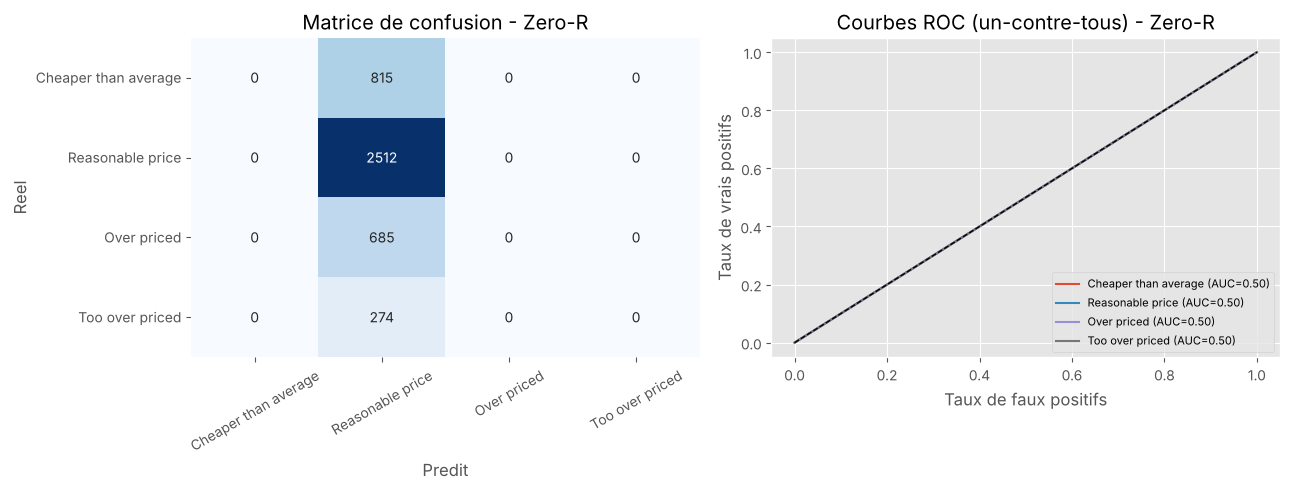

In [6]:
res_zero = evaluate_model(make_model_pipeline("Zero-R"),
                         X_train, y_train, X_test, y_test,
                         name="Zero-R", cv=5, plot=True, save_dir=FIG)

## 6. Validation de `evaluate_model()` sur les 5 familles de modèles

Ce passage n'est **pas** la comparaison finale : les modèles sont lancés avec leurs paramètres **par défaut**, sans optimisation. Il sert à (1) prouver que `evaluate_model()` et les préprocesseurs fonctionnent pour chaque famille (y compris `decision_function` du SVM pour la courbe ROC), et (2) donner une première idée à l'équipe. L'optimisation (GridSearchCV / RandomizedSearchCV, K ≥ 5) est assurée ensuite avec `tune_model()`.

In [7]:
all_results = [res_zero]
for name in ["KNN", "Decision Tree", "Random Forest", "GaussianNB", "MultinomialNB", "SVM"]:
    r = evaluate_model(make_model_pipeline(name), X_train, y_train, X_test, y_test,
                       name=name, cv=5, plot=False, verbose=False)
    all_results.append(r)
    print(f"{name:15s} acc={r['accuracy']:.3f}  F1macro={r['f1_macro']:.3f}  AUC={r['roc_auc_macro_ovr']:.3f}")

KNN             acc=0.599  F1macro=0.439  AUC=0.730


Decision Tree   acc=0.678  F1macro=0.604  AUC=0.732


Random Forest   acc=0.702  F1macro=0.563  AUC=0.877


GaussianNB      acc=0.596  F1macro=0.331  AUC=0.697


MultinomialNB   acc=0.592  F1macro=0.261  AUC=0.658


SVM             acc=0.711  F1macro=0.557  AUC=0.869


,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_macro_ovr,cv_accuracy_mean,cv_accuracy_std,cv_f1_macro_mean,cv_f1_macro_std
model_name,,,,,,,,,
Zero-R,0.5861,0.1465,0.2500,0.1848,0.5000,0.5861,0.0001,0.1848,0.0000
KNN,0.5994,0.5231,0.4107,0.4389,0.7301,0.6044,0.0046,0.4402,0.0115
Decision Tree,0.6783,0.6083,0.6005,0.6039,0.7316,0.6572,0.0096,0.5744,0.0056
Random Forest,0.7016,0.6886,0.5135,0.5631,0.8772,0.6940,0.0072,0.5503,0.0128
GaussianNB,0.5964,0.4616,0.3387,0.3308,0.6973,0.5870,0.0070,0.3197,0.0093
MultinomialNB,0.5919,0.4398,0.2895,0.2608,0.6579,0.5944,0.0010,0.2651,0.0102
SVM,0.7114,0.6929,0.5071,0.5572,0.8688,0.6999,0.0059,0.5362,0.0133


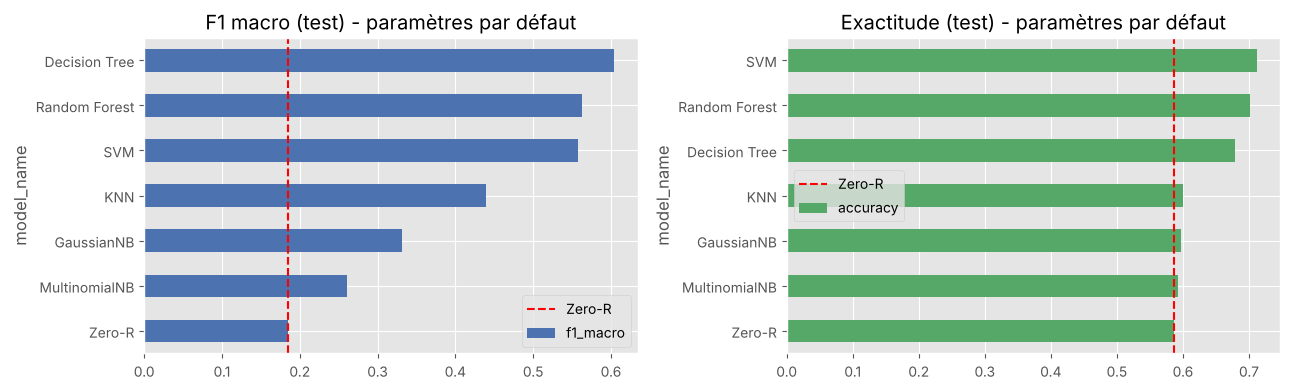

In [8]:
table = results_table(all_results)
table.to_csv(ROOT / "docs" / "m3_default_models_summary.csv")
display(table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
table["f1_macro"].sort_values().plot(kind="barh", ax=axes[0], color="#4c72b0")
axes[0].axvline(table.loc["Zero-R", "f1_macro"], color="red", ls="--", label="Zero-R")
axes[0].set_title("F1 macro (test) - paramètres par défaut"); axes[0].legend()
table["accuracy"].sort_values().plot(kind="barh", ax=axes[1], color="#55a868")
axes[1].axvline(table.loc["Zero-R", "accuracy"], color="red", ls="--", label="Zero-R")
axes[1].set_title("Exactitude (test) - paramètres par défaut"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "m3_default_models_comparison.png", dpi=130); plt.show()

### Exemple de matrice de confusion et de courbes ROC (SVM, paramètres par défaut)

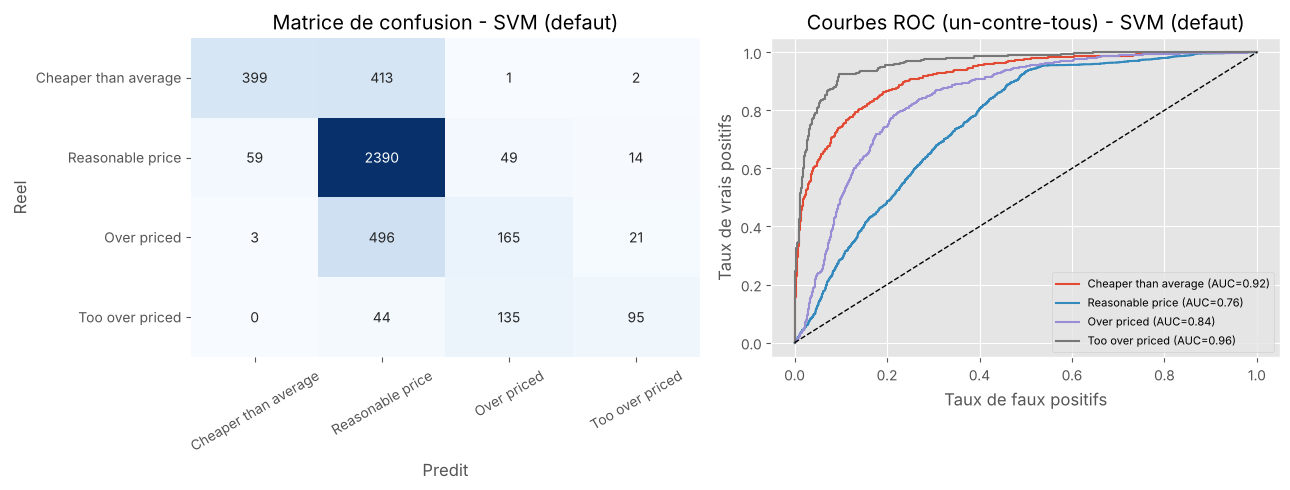

In [9]:
_ = evaluate_model(make_model_pipeline("SVM"), X_train, y_train, X_test, y_test,
                  name="SVM (defaut)", cv=5, plot=True, save_dir=FIG, verbose=False)

## 7. Test de `tune_model()` (GridSearchCV, K = 5)

Petit test pour vérifier que l'outil d'optimisation fonctionne, avec une grille réduite sur K-NN. Les grilles complètes sont dans `PARAM_GRIDS` (`src/m3_tools.py`) ; chaque membre en charge d'un modèle les ajuste.

In [10]:
small_grid = {"clf__n_neighbors": [5, 11, 21], "clf__weights": ["uniform", "distance"]}
search = tune_model("KNN", X_train, y_train, search="grid", cv=5, param_grid=small_grid)
print("Meilleurs paramètres :", search.best_params_)
print("F1 macro CV (5 plis) :", round(search.best_score_, 4))

Meilleurs paramètres : {'clf__n_neighbors': 5, 'clf__weights': 'distance'}
F1 macro CV (5 plis) : 0.4673


## 8. Génération de `model/feature_schema.json`

Le schéma contient l'ordre exact des colonnes, les plages numériques, les valeurs de `zipcode`, les noms de classes et les colonnes interdites. Il est utilisé par M5 (validation côté serveur) et M6 (formulaire).

In [11]:
schema = build_feature_schema(X)
(ROOT / "model").mkdir(exist_ok=True)
with open(ROOT / "model" / "feature_schema.json", "w", encoding="utf-8") as f:
    json.dump(schema, f, indent=2, ensure_ascii=False)

print("Ordre des colonnes :", schema["feature_order"])
print("Nb de zipcodes     :", len(schema["categorical"]["zipcode"]))
pd.DataFrame(schema["numerical"]).T

Ordre des colonnes : ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'zipcode', 'renovated']
Nb de zipcodes     : 70


,min,max,median,integer
price,75000.0,7700000.0,450000.0,True
bedrooms,0.0,11.0,3.0,True
bathrooms,0.0,8.0,2.25,False
sqft_living,370.0,13540.0,1920.0,True
sqft_lot,520.0,1651359.0,7614.5,True
floors,1.0,3.5,1.5,False
waterfront,0.0,1.0,0.0,True
view,0.0,4.0,0.0,True
condition,1.0,5.0,3.0,True
grade,3.0,13.0,7.0,True


### Test de bout en bout du schéma : une maison brute -> pipeline -> catégorie

On simule ce que fera le backend : un dictionnaire JSON (zipcode en nombre, ordre quelconque) est converti avec `prepare_input()`, puis passé à un pipeline entraîné.

In [12]:
raw = {"zipcode": 98115, "price": 450000, "bedrooms": 3, "bathrooms": 2.0, "sqft_living": 1800,
       "sqft_lot": 5000, "floors": 1.0, "waterfront": 0, "view": 0, "condition": 3, "grade": 7,
       "sqft_above": 1800, "sqft_basement": 0, "yr_built": 1960, "renovated": 0}
row = prepare_input(pd.DataFrame([raw]))
assert list(row.columns) == schema["feature_order"]

model = make_model_pipeline("Decision Tree").fit(X_train, y_train)
pred = int(model.predict(row)[0])
print("Prédiction :", pred, "->", LABELS[pred])

# Même maison, prix multiplié par 2 : la catégorie doit pouvoir monter
row2 = row.copy(); row2["price"] = 900000
print("Prix x2    :", LABELS[int(model.predict(row2)[0])])

Prédiction : 0 -> Cheaper than average
Prix x2    : Too over priced


## 9. Récapitulatif et remise aux autres membres

**Fichiers produits**
- `src/m3_tools.py` : `load_labeled`, `split_xy`, `prepare_input`, `get_preprocessor`, `MODEL_ZOO`, `make_model_pipeline`, `evaluate_model`, `results_table`, `PARAM_GRIDS`, `tune_model`, `build_feature_schema`
- `data/split/` : `X_train.csv`, `X_test.csv`, `y_train.csv`, `y_test.csv` (index = ligne de `house_labeled.csv`)
- `model/feature_schema.json`

**Consignes d'utilisation**
1. Toujours lire les données avec `load_labeled()` (`zipcode` en texte).
2. Utiliser le même découpage (`train_test_split(..., test_size=0.2, stratify=y, random_state=42)`) ou relire `data/split/` avec `dtype={"zipcode": str}`.
3. Chaque modèle se construit avec `make_model_pipeline("<nom>")` ; ne jamais ajuster un préprocesseur sur le jeu de test.
4. Évaluer avec `evaluate_model()` ; optimiser avec `tune_model()` (K ≥ 5, score F1 macro).
5. Sauvegarder le **pipeline complet** avec `joblib` et noter la version de scikit-learn.

**Points d'attention pour l'équipe**
- Classe 3 minoritaire (6,4 %) : privilégier le F1 macro ; essayer `class_weight="balanced"` pour les modèles qui le supportent (arbre, forêt, SVM).
- `price`, `sqft_living` et `zipcode` servent aussi à construire la cible : une partie du score reflète la règle de construction (limite à discuter dans le rapport).
- Les modèles à distance (K-NN, SVM) voient les 70 colonnes one-hot de `zipcode` : leur comportement est à commenter.